# De razones a metros: reconstruir el patrón absoluto de un tiro y contrastarlo con el artículo

**Nivel 2: El método en la práctica** · Requiere: 01-the-data/01-the-corpus-and-the-cases · Tiempo de lectura: unos 20 minutos

## Objetivos

La ecuación clásica del tamaño medio necesita un volumen de roca y una masa de explosivo en metros y kilogramos, pero el corpus publicado entrega solo razones adimensionales. Este cuaderno muestra cómo el motor recupera el patrón absoluto, cómo prueba la recuperación contra la propia prosa del artículo, y qué hace cuando nada fija la escala.

Al terminar habrá:

- reconstruido a mano un patrón y comprobado que coincide con `reconstruct_pattern` del motor;
- ejecutado la verificación de la reconstrucción contra todas las afirmaciones dimensionales de la prosa de la fuente;
- visto fallar la verificación cuando el diámetro de perforación es incorrecto, que es lo que le da poder;
- visto el único sitio que el motor se niega a reconstruir, y el artefacto versionado que registra la negativa.

## Preparación

Instale los paquetes con los pines exactos de `notebooks/requirements.txt`. El motor es `blastfrag`, publicado en PyPI; los otros paquetes son su base numérica y la biblioteca de gráficos.

```bash
pip install blastfrag==0.4.0 numpy==2.5.3 matplotlib==3.11.2
```

Esta celda aún no importa nada del cuaderno: lee las versiones instaladas desde los metadatos de los paquetes y las imprime, de modo que la salida registra qué motor produjo cada número que sigue.

In [1]:
# Imprima la versión instalada de cada paquete que usa este cuaderno
from importlib.metadata import version

for name in ("blastfrag", "numpy", "matplotlib",):
    print(f"{name}=={version(name)}")

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Datos

| Fuente | Titular y URL | Clase de licencia | Archivo que lee el cuaderno |
|---|---|---|---|
| El corpus y las narrativas de los sitios (diámetros, alturas de banco, bordos) | Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 | hechos numéricos reutilizados con cita; el artículo nunca se distribuye | la tabla y el registro `SITE_GEOMETRY` dentro del paquete `blastfrag` |
| El control negativo de geometría | este repositorio (MIT), escrito por la ejecución offline | la licencia propia del producto | `data/derived/real-miami/case.json` |

Cada entrada del registro guarda el diámetro de perforación de un sitio, **cómo se obtuvo** (citado del artículo, derivado de una altura de banco declarada, o elegido), y las afirmaciones dimensionales que el artículo hace de ese sitio, como rangos en metros.

## Método

Las razones de un tiro se definen respecto de su bordo `B` y su diámetro de perforación `D`, de modo que una longitud conocida (el diámetro) fija todas las demás:

- bordo `B = (B/D) * D`
- espaciamiento `S = (S/B) * B`
- altura de banco `H = (H/B) * B`
- taco `T = (T/B) * B`

El volumen de roca por pozo es `V = B * S * H` y la masa de explosivo es `Q = Pf * V`, con `Pf` el factor de carga que el corpus imprime directamente (Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957). El diámetro es la única cantidad que no se puede calcular desde la tabla, así que se lee de la prosa de cada sitio y se guarda en el registro.

### Paso 1: el registro

La celda imprime, para cada sitio, el diámetro y las primeras palabras de la frase que da su fuente. Aparecen tres tipos de fuente: un diámetro citado del artículo, un diámetro derivado de una altura de banco declarada (marcado `DERIVED`), y ningún diámetro (marcado `NOT PUBLISHED`).

In [2]:
# Importaciones, y luego el registro de geometría de sitios que trae el motor
import dataclasses
import json
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt

DERIVED = Path("../../../data/derived")
train = bf.load_training_corpus()
sites = sorted({b.site for b in train})
print(f"{'sitio':<14}{'D (mm)':>8}  fuente del diámetro")
for site in sites:
    geometry = bf.SITE_GEOMETRY[site]
    diameter = "-" if geometry.hole_diameter_mm is None else f"{geometry.hole_diameter_mm:g}"
    print(f"{site:<14}{diameter:>8}  {geometry.diameter_source[:70]}")

sitio           D (mm)  fuente del diámetro
Akdaglar            89  "The drillhole diameter is 89 mm"
Dongri-Buzurg      100  "The hole diameter was 100 mm and bench height was 6 to 11 m"
Enusa              165  "Hole diameters for the Enusa and Reocin mines were 165 and 229 mm"
Miami                -  NOT PUBLISHED and not derivable. The paper gives no diameter and no ab
Mrica               76  "The hole diameter was 76 mm and bench height was 10 to 15 m"
Murgul             165  "The drillhole diameter applied was 165 mm"
Ozmert              89  "The hole diameter is 89 mm"
Reocin             229  "Hole diameters for the Enusa and Reocin mines were 165 and 229 mm"
Reocin-UG         91.2  DERIVED, not published. The paper states an 18 m bench for the Reocin 
Soma               210  "The diameter of the blast holes was 21 cm"


### Paso 2: un tiro a mano

La celda aplica las cuatro fórmulas anteriores al tiro `En1` (Enusa, diámetro 165 mm) con aritmética simple, y luego pide al motor el mismo patrón y compara ambos. La llamada del motor es `reconstruct_pattern`; el cálculo a mano existe solo para mostrar que no hay un paso oculto.

In [3]:
# Reconstruir En1 a mano y con el motor
blast = next(b for b in train if b.blast_id == "En1")
diameter_m = bf.SITE_GEOMETRY[blast.site].hole_diameter_mm / 1000.0
burden = blast.B_over_D * diameter_m
by_hand = {
    "burden_m": burden,
    "spacing_m": blast.S_over_B * burden,
    "bench_height_m": blast.H_over_B * burden,
    "stemming_m": blast.T_over_B * burden,
}
pattern = bf.reconstruct_pattern(blast)
for name, value in by_hand.items():
    print(f"{name:<15} a mano {value:8.4f}   motor {getattr(pattern, name):8.4f}   igual: {value == getattr(pattern, name)}")
print(f"volumen de roca por pozo V = {pattern.rock_volume_m3:.2f} m3")
print(f"masa de explosivo por pozo Q = {pattern.charge_mass_kg:.2f} kg  (Pf = {pattern.powder_factor_kg_m3} kg/m3)")

burden_m        a mano   4.4996   motor   4.4996   igual: True
spacing_m       a mano   5.5794   motor   5.5794   igual: True
bench_height_m  a mano   5.9844   motor   5.9844   igual: True
stemming_m      a mano   3.5096   motor   3.5096   igual: True
volumen de roca por pozo V = 150.24 m3
masa de explosivo por pozo Q = 72.11 kg  (Pf = 0.48 kg/m3)


### Paso 3: probar la reconstrucción contra el artículo

Si el diámetro fuera incorrecto, todas las longitudes serían incorrectas por el mismo factor. La prosa del artículo declara algunas longitudes directamente (por ejemplo "la altura de banco fue de 6 m"). `verify_reconstruction` reconstruye todos los tiros de un sitio y exige que cada rango declarado contenga el rango reconstruido, permitiendo solo la holgura que produce la impresión de las razones con dos decimales. Lanza un `AssertionError` ante cualquier violación, por lo que funciona como compuerta.

In [4]:
# Ejecutar la verificación sobre todo el corpus y listar cada restricción dimensional que probó
report = bf.verify_reconstruction(train)
rows = []
for site, entry in report.items():
    for check in entry["checks"]:
        rows.append((site, check))
print(f"{'sitio':<14}{'magnitud':<16}{'artículo declara (m)':>22}{'reconstruido (m)':>24}  ok")
for site, check in rows:
    stated = f"{check['stated'][0]:g} - {check['stated'][1]:g}"
    got = f"{check['reconstructed'][0]:g} - {check['reconstructed'][1]:g}"
    print(f"{site:<14}{check['quantity']:<16}{stated:>22}{got:>24}  {check['ok']}")
print("restricciones probadas:", len(rows), "| satisfechas:", sum(c["ok"] for _, c in rows))

sitio         magnitud          artículo declara (m)        reconstruido (m)  ok
Akdaglar      burden_m                     1.5 - 2.6               1.6 - 2.5  True
Dongri-Buzurg bench_height_m                  6 - 11                  6 - 11  True
Dongri-Buzurg burden_m                       2 - 2.5                 2 - 2.5  True
Dongri-Buzurg spacing_m                    1.8 - 3.5               2.5 - 3.5  True
Enusa         bench_height_m                   6 - 6           5.984 - 5.984  True
Mrica         bench_height_m                 10 - 15         14.998 - 14.999  True
Murgul        bench_height_m              12 - 12.05         11.999 - 12.014  True
Murgul        burden_m                       4.5 - 5                 4.5 - 5  True
Murgul        spacing_m                    4.5 - 5.5             4.5 - 5.499  True
Ozmert        burden_m                         2 - 3                   2 - 3  True
Ozmert        spacing_m                      2.5 - 3                 2.5 - 3  True
Reocin

### Paso 4: ¿tiene poder la verificación?

Una verificación que no puede fallar no prueba nada. La narrativa de Soma es la prueba útil: una lectura alternativa del artículo tiene un pozo de 175 mm. La celda reemplaza el diámetro de Soma en el registro por otros valores, ejecuta la misma verificación y restaura el original en un bloque `finally` para que nada se filtre a las celdas siguientes.

In [5]:
# Probar diámetros incorrectos para Soma; el registro se restaura después
soma = [b for b in train if b.site == "Soma"]
original = bf.SITE_GEOMETRY["Soma"]
outcome = {}
try:
    for diameter in (175.0, 190.0, original.hole_diameter_mm, 230.0):
        bf.SITE_GEOMETRY["Soma"] = dataclasses.replace(original, hole_diameter_mm=diameter)
        try:
            bf.verify_reconstruction(soma)
            outcome[diameter] = "pasa"
        except AssertionError:
            outcome[diameter] = "falla"
finally:
    bf.SITE_GEOMETRY["Soma"] = original
for diameter, verdict in outcome.items():
    print(f"D = {diameter:g} mm: {verdict}")

D = 175 mm: falla
D = 190 mm: falla
D = 210 mm: pasa
D = 230 mm: falla


### Paso 5: donde nada fija la escala

Miami no publica diámetro de perforación ni longitud absoluta alguna, así que no existe una reconstrucción honesta. El motor lanza `GeometryUnavailable` en vez de adivinar, y `has_absolute_geometry` es el predicado que usa cada brazo que necesita un volumen para decidir si responde. La celda cuenta los tiros que lo cumplen y lee el artefacto versionado del caso Miami, que lleva la misma negativa en ambos idiomas.

In [6]:
# Contar los tiros con geometría resoluble y leer la negativa para Miami
resolvable = [b for b in train if bf.has_absolute_geometry(b)]
print("tiros con geometría absoluta:", len(resolvable), "de", len(train))
miami = next(b for b in train if b.site == "Miami")
try:
    bf.reconstruct_pattern(miami)
except bf.GeometryUnavailable as refusal:
    print("negativa del motor:", str(refusal)[:110], "...")
artifact = json.loads((DERIVED / "real-miami" / "case.json").read_text(encoding="utf-8"))
print("razón versionada (en):", artifact["case"]["reason"]["en"][:110], "...")
print("razón versionada (es):", artifact["case"]["reason"]["es"][:110], "...")

tiros con geometría absoluta: 91 de 97
negativa del motor: Mi1: Miami Mine, Arizona, USA publishes no hole diameter and no absolute dimension, so its scale cannot be fix ...
razón versionada (en): Nothing in the source fixes this site's absolute scale: no hole diameter, no bench height, no burden. Every mo ...
razón versionada (es): Nada en la fuente fija la escala absoluta de este sitio: sin diámetro de perforación, sin altura de banco, sin ...


La última celda del método dibuja el bordo y la altura de banco reconstruidos de cada tiro resoluble, coloreados por sitio, para que la escala que verá la ecuación clásica sea visible antes de usarla.

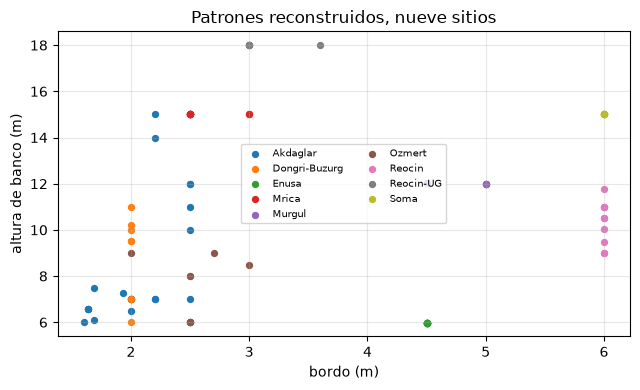

In [7]:
# Bordo contra altura de banco en metros, un color por sitio
fig, ax = plt.subplots(figsize=(6.5, 4))
for site in sites:
    members = [b for b in resolvable if b.site == site]
    if not members:
        continue
    patterns = [bf.reconstruct_pattern(b) for b in members]
    ax.scatter([p.burden_m for p in patterns], [p.bench_height_m for p in patterns], s=18, label=site)
ax.set_xlabel("bordo (m)")
ax.set_ylabel("altura de banco (m)")
ax.set_title("Patrones reconstruidos, nueve sitios")
ax.legend(fontsize=7, ncol=2)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## Resultados

**La reconstrucción es aritmética exacta sobre una longitud guardada.** El cálculo a mano y el motor coinciden hasta el último dígito en el tiro de Enusa. El único juicio en toda la recuperación es el diámetro de perforación, y el registro anota para cada sitio si fue citado, derivado o ausente.

**La verificación no es una formalidad.** Las 15 afirmaciones dimensionales que hace la prosa de la fuente se cumplen con el registro, y la prueba de Soma muestra que la misma verificación falla con 175, 190 y 230 mm y solo pasa con los 210 mm registrados. Un diámetro incorrecto no puede esconderse. Lo que la verificación no puede hacer es elegir entre dos lecturas que cumplen ambas la prosa; la única ambigüedad de Soma que registra el motor (qué bordo pretendían los autores) se lleva como nota del caso, no se resuelve aquí.

**La negativa es un resultado.** 91 de los 97 tiros tienen geometría resoluble. Los seis tiros de Miami no, y el motor, y el artefacto versionado, lo dicen en ambos idiomas en lugar de devolver un número. Cada cuaderno posterior hereda esto: un brazo que necesita un volumen se abstiene en Miami.

**Qué no muestra esto.** Coincidir con la prosa del artículo prueba que las longitudes son consistentes con lo que escribieron los autores, no que las hayan medido correctamente, y no dice nada sobre la exactitud de ninguna predicción hecha con ellas.

## Resumen

- Un diámetro guardado por sitio convierte cada razón en metros; la aritmética son cuatro multiplicaciones.
- `verify_reconstruction` prueba el resultado contra 15 afirmaciones de la prosa de la fuente y falla cuando el diámetro es incorrecto.
- Donde no se publica ninguna longitud (Miami) el motor se niega, y quedan 91 de 97 tiros utilizables por los brazos clásicos.
- Siguiente: el cuaderno 03 abre la compuerta de integridad sobre el propio corpus y el control negativo que alimenta la negativa (nivel 4).

## Referencias

- Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (el corpus, las narrativas de los sitios y las razones impresas)
- `blastfrag` 0.4.0, el motor, en PyPI: https://pypi.org/project/blastfrag/